In [1]:
import pandas as pd
import nltk

# Download required NLTK lexical resources quietly
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

# Inspect spam.csv (handle latin-1 encoding typical of SMS Spam Collection)
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
print("Raw spam.csv shape:", df_spam.shape)
print("Columns:", df_spam.columns.tolist())
display(df_spam.head())

Raw spam.csv shape: (5572, 5)
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Records before deduplication: 5572 | After deduplication: 5169
--- Class Distribution ---
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64

TF-IDF Matrix Shape — Train: (4135, 3000) | Test: (1034, 3000)

--- NLP Text Classification Benchmark (Test Set) ---


,Model,Accuracy,Precision (Spam),Recall (Spam),F1-Score (Spam)
0,Multinomial Naive Bayes,0.9700,0.9717,0.7863,0.8692
1,Logistic Regression,0.9613,0.9596,0.7252,0.8261
2,Linear SVM (LinearSVC),0.9768,0.9496,0.8626,0.9040


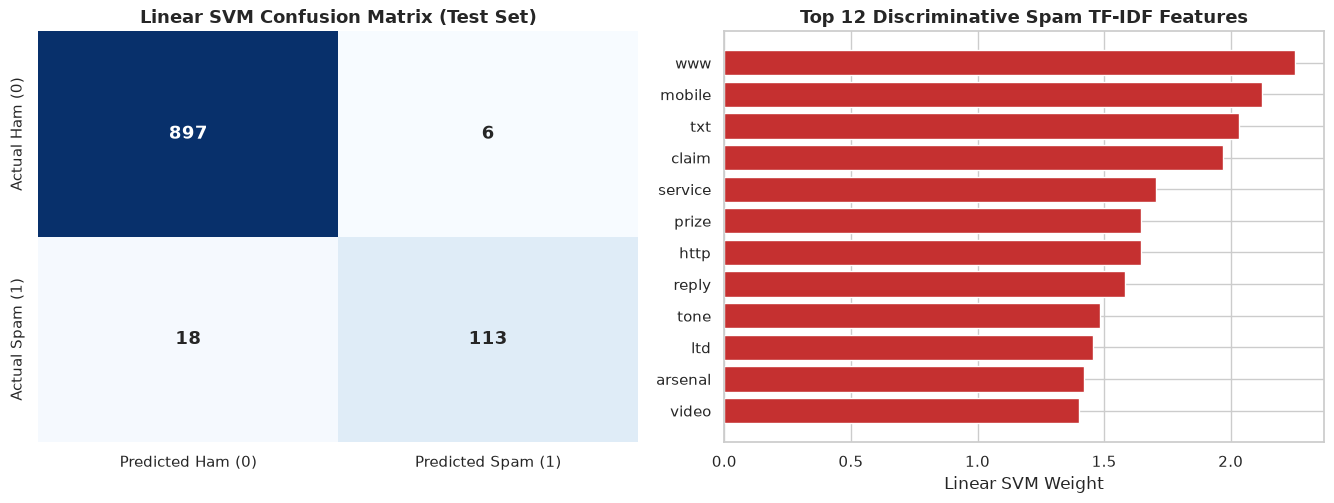

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# 1. Clean Schema & Deduplicate
df_nlp = df_spam[['v1', 'v2']].copy()
df_nlp.columns = ['label', 'text']
before_dedup = len(df_nlp)
df_nlp.drop_duplicates(subset=['text'], inplace=True)
df_nlp['target'] = df_nlp['label'].map({'ham': 0, 'spam': 1})

print(f"Records before deduplication: {before_dedup} | After deduplication: {len(df_nlp)}")
print("--- Class Distribution ---")
print(df_nlp['label'].value_counts(normalize=True).round(4) * 100)

# 2. NLTK Preprocessing Pipeline (Lowercase -> Regex Clean -> Tokenize -> Stopwords -> Lemmatize)
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = re.sub(r'[^a-zA-Z\s]', ' ', str(text).lower())
    tokens = word_tokenize(text)
    cleaned = [
        lemmatizer.lemmatize(tok)
        for tok in tokens
        if tok not in stop_words and len(tok) > 2
    ]
    return " ".join(cleaned)

df_nlp['clean_text'] = df_nlp['text'].apply(preprocess_text)

# 3. Stratified 80/20 Split BEFORE TF-IDF Vectorization (Zero Vocabulary Leakage)
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df_nlp['clean_text'], df_nlp['target'],
    test_size=0.20, stratify=df_nlp['target'], random_state=42
)

tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train_txt)
X_test_tfidf = tfidf.transform(X_test_txt)
print(f"\nTF-IDF Matrix Shape — Train: {X_train_tfidf.shape} | Test: {X_test_tfidf.shape}")

# 4. Train & Evaluate NLP Classifiers
nlp_models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM (LinearSVC)": LinearSVC(random_state=42)
}

nlp_results = []
for name, clf in nlp_models.items():
    clf.fit(X_train_tfidf, y_train)
    y_pred = clf.predict(X_test_tfidf)
    nlp_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision (Spam)": round(precision_score(y_test, y_pred), 4),
        "Recall (Spam)": round(recall_score(y_test, y_pred), 4),
        "F1-Score (Spam)": round(f1_score(y_test, y_pred), 4)
    })

df_nlp_eval = pd.DataFrame(nlp_results)
print("\n--- NLP Text Classification Benchmark (Test Set) ---")
display(df_nlp_eval)

# 5. Two-Panel Diagnostic Plot (Best Model Confusion Matrix + Top Spam TF-IDF Terms)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

best_preds = nlp_models["Linear SVM (LinearSVC)"].predict(X_test_tfidf)
cm = confusion_matrix(y_test, best_preds)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Predicted Ham (0)", "Predicted Spam (1)"],
    yticklabels=["Actual Ham (0)", "Actual Spam (1)"],
    annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title("Linear SVM Confusion Matrix (Test Set)", fontsize=13, fontweight="bold")

# Top 12 discriminative spam features by Linear SVM weight
feature_names = np.array(tfidf.get_feature_names_out())
coefs = nlp_models["Linear SVM (LinearSVC)"].coef_[0]
top_idx = np.argsort(coefs)[-12:]
axes[1].barh(feature_names[top_idx], coefs[top_idx], color="#c53030")
axes[1].set_title("Top 12 Discriminative Spam TF-IDF Features", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Linear SVM Weight")

plt.tight_layout()
plt.show()